In [228]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = 'GPU-65b68a8a-200e-11d6-005d-c4c55d998466'

import sys
#sys.path.insert(0,'/users/kobbad/feat_leakage/deepSEA_negatives')
from model import Beluga
import torch
import pandas as pd
from bpnetlite.io import extract_loci
from tangermeme.ersatz import dinucleotide_shuffle
from tangermeme.ersatz import substitute, multisubstitute
import torch
from torch import nn
from tangermeme.deep_lift_shap import deep_lift_shap
from tangermeme.utils import random_one_hot, characters
from tangermeme.ersatz import substitute
from matplotlib import pyplot as plt
from tangermeme.plot import plot_logo
from torch.utils.data import Dataset, DataLoader
import random
from model import SyntheticMotifCountDataset
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import matplotlib
from sklearn.metrics import r2_score
from tqdm import tqdm
from fuzzywuzzy import fuzz
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


# from mytangermeme.ersatz import dinucleotide_shuffle as my_dinucleotide_shuffle

In [96]:
import torch
from model import (Beluga, expand_tasks_to_2003, 
                   train_ap1_motif_counting, evaluate_ap1_counting, sigmoid_to_count,
                   plot_training_curves, fuzzy_substring_match, measure_motif_insertion_effect)

In [3]:
# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Load the original Beluga model
print("Loading original Beluga model...")
mdl = Beluga()
mdl.load_state_dict(torch.load('../deepSEA_negatives/deepsea.beluga.pth', map_location=device))

print(f"Original model output shape: {mdl.model[1][4][1].out_features}")  # Should be 2002

# Expand to 2003 tasks (adding AP1 motif counting)
print("Expanding model to 2003 tasks...")

# Option 1: Recommended approach - removes sigmoid for counting task
mdl = expand_tasks_to_2003(mdl)
print(f"Using BelugaWithCounting model (sigmoid removed for counting task)")


Using device: cuda
Loading original Beluga model...
Original model output shape: 2002
Expanding model to 2003 tasks...
Using BelugaWithCounting model (sigmoid removed for counting task)


In [4]:
# Define the AP1 motif
ap1_motif = "ATGAGTCAC"  # This is the AP1 motif from your notebook

# Train the AP1 motif counting task
print(f"\nTraining AP1 motif counting task for motif: {ap1_motif}")
trained_model, history = train_ap1_motif_counting(
    model=mdl,
    num_epochs=5,  # Use fewer epochs for demo
    batch_size=32,
    learning_rate=1e-4,
    motif=ap1_motif,
    max_count=5,
    train_size=5000,  # Smaller dataset for demo
    val_size=1000,
    device=device,
    freeze_backbone=True  # Only train the final layer
)



Training AP1 motif counting task for motif: ATGAGTCAC
Freezing backbone - only training final layer
Training AP1 motif counting for 5 epochs...
Motif: ATGAGTCAC, Max count: 5
Train size: 5000, Val size: 1000
Epoch 1/5, Batch 0, Loss: 5.2117
Epoch 1/5, Batch 100, Loss: 2.1937
Epoch 1/5:
  Train Loss: 2.7054, Train MAE: 1.3552, Train R: 0.3637
  Val Loss: 2.4275, Val MAE: 1.2665, Val R: 0.5709
Epoch 2/5, Batch 0, Loss: 1.5082
Epoch 2/5, Batch 100, Loss: 1.2495
Epoch 2/5:
  Train Loss: 1.6975, Train MAE: 1.0464, Train R: 0.6532
  Val Loss: 1.7575, Val MAE: 1.0714, Val R: 0.6858
Epoch 3/5, Batch 0, Loss: 1.5939
Epoch 3/5, Batch 100, Loss: 1.8255
Epoch 3/5:
  Train Loss: 1.4853, Train MAE: 0.9801, Train R: 0.7082
  Val Loss: 1.7193, Val MAE: 1.0381, Val R: 0.7647
Epoch 4/5, Batch 0, Loss: 1.1177
Epoch 4/5, Batch 100, Loss: 1.5026
Epoch 4/5:
  Train Loss: 1.3125, Train MAE: 0.9148, Train R: 0.7436
  Val Loss: 1.5712, Val MAE: 0.9882, Val R: 0.7640
Epoch 5/5, Batch 0, Loss: 1.2091
Epoch 5/5,

In [7]:
# Generate test dataset with sequences containing 1-5 AP1 motifs
ap1_motif = "ATGAGTCAC"
test_size = 1000

print("Generating test sequences with AP1 motifs...")
test_dataset = SyntheticMotifCountDataset(
    N=test_size, 
    L=2000, 
    motif=ap1_motif, 
    max_count=5, 
    seed=42  # Different seed from training
)

# Create DataLoader
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Collect predictions and true labels
predictions = []
true_labels = []

print("Generating predictions...")
trained_model.eval()
trained_model.to(device)

with torch.no_grad():
    for batch_idx, (sequences, labels) in enumerate(test_loader):
        sequences = sequences.to(device)
        
        # Get model predictions
        outputs = trained_model(sequences)
        
        # Extract the counting task predictions (index 2002)
        count_predictions = outputs[:, 2002].cpu().numpy()
        
        predictions.extend(count_predictions)
        true_labels.extend(labels.numpy())
        
        if batch_idx % 10 == 0:
            print(f"Processed batch {batch_idx}/{len(test_loader)}")

# Convert to numpy arrays
predictions = np.array(predictions)
true_labels = np.array(true_labels)

Generating test sequences with AP1 motifs...
Generating predictions...
Processed batch 0/16
Processed batch 10/16


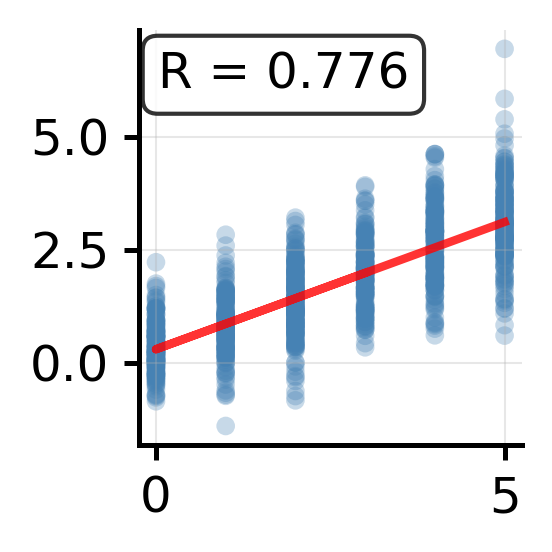

In [17]:
# Set up matplotlib for publication-quality output
matplotlib.rcParams['pdf.fonttype'] = 42  # Ensures text is saved as text, not paths
matplotlib.rcParams['ps.fonttype'] = 42   # For EPS compatibility
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['axes.linewidth'] = 1.2
matplotlib.rcParams['xtick.major.width'] = 1.2
matplotlib.rcParams['ytick.major.width'] = 1.2

# Create the figure with appropriate size for publication
fig, ax = plt.subplots(figsize=(2, 2), dpi=300)

# Create the scatter plot
scatter = ax.scatter(true_labels, predictions, alpha=0.3, s=20, color='steelblue', edgecolors='none')

# Calculate best fit line
slope, intercept, r_value, p_value, std_err = stats.linregress(true_labels, predictions)
line = slope * true_labels + intercept

# Plot the best fit line
ax.plot(true_labels, line, 'r-', linewidth=2, alpha=0.8, label=f'Best fit line')

# Calculate R²
r_squared = r2_score(true_labels, predictions)
pearson_r = stats.pearsonr(true_labels, predictions)[0]

# Add R² as text annotation
ax.text(0.05, 0.95, f'R = {pearson_r:.3f}', transform=ax.transAxes, 
        fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Improve the appearance
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)

# Make sure the plot looks clean
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Tight layout to prevent clipping
plt.tight_layout()

# Save as PDF with high quality settings
plt.savefig('scatter_plot_with_fit.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight', 
            facecolor='white', 
            edgecolor='none',
            backend='pdf')

# Display the plot
plt.show()

In [35]:
X = random_one_hot((1, 4, 2000)).type(torch.float32)
X = multisubstitute(X,[ap1_motif, ap1_motif], 30)

In [36]:
X_attr = deep_lift_shap(mdl, X, target=2002, random_state=0)

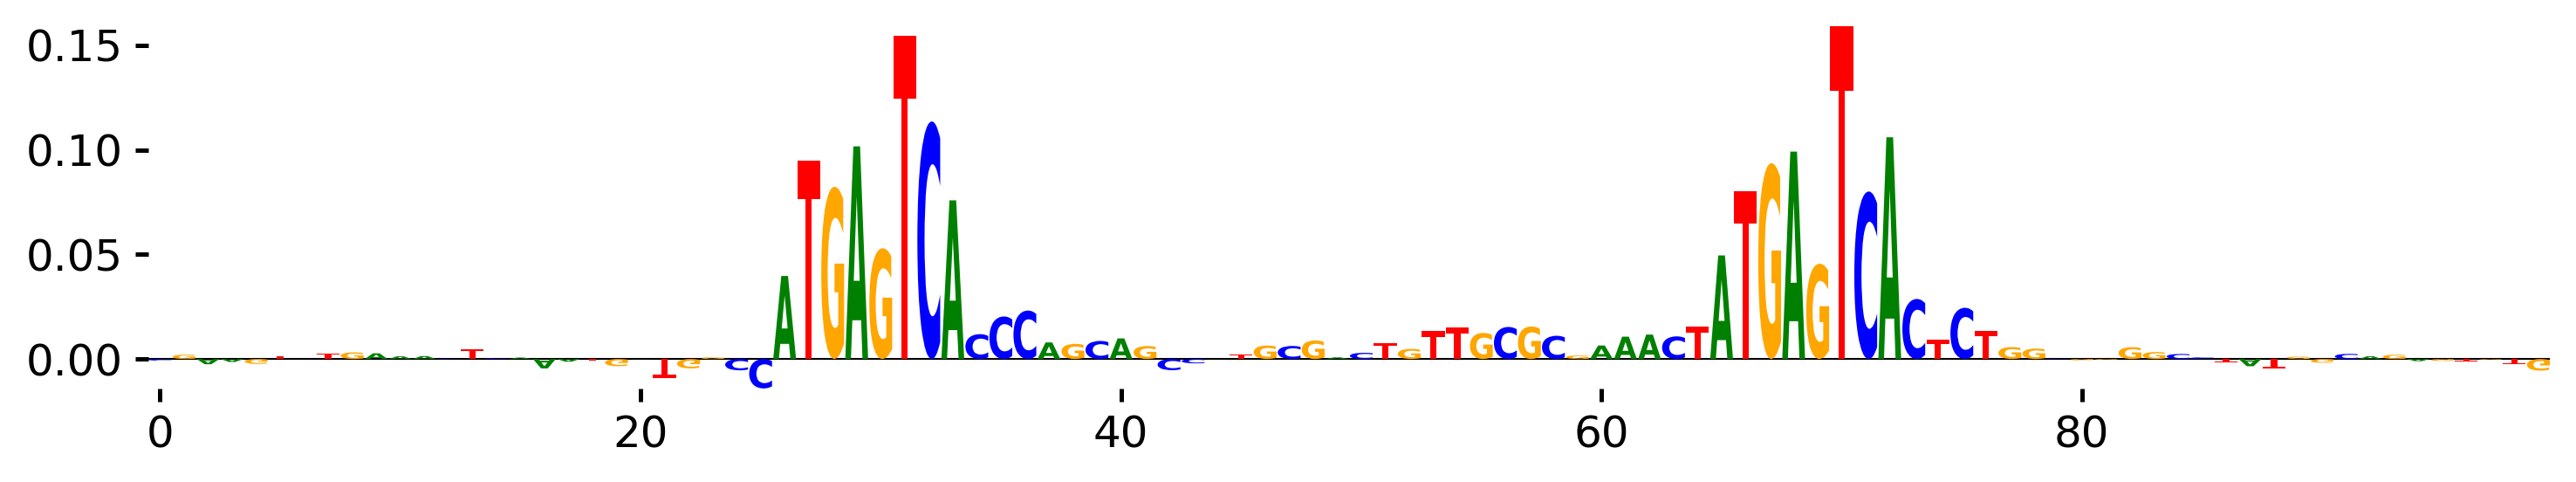

In [38]:
# Set up matplotlib for publication-quality output with text recognition
matplotlib.rcParams['pdf.fonttype'] = 42  # Ensures text is saved as text, not paths
matplotlib.rcParams['ps.fonttype'] = 42   # For EPS compatibility
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['axes.linewidth'] = 1.2

# Create the figure
plt.figure(figsize=(10, 2), dpi=300)
ax = plt.subplot(111)

# Your plot
plot_logo(X_attr[0, :, 950:1050], ax=ax)

# Improve layout
plt.tight_layout()

# Save as PDF with high quality settings and text recognition
plt.savefig('logo_plot_just_ap1.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight', 
            facecolor='white', 
            edgecolor='none',
            backend='pdf')

# Display the plot
plt.show()

Now testing the other motifs for leakage

In [47]:
annots = pd.read_excel("../ap1_counting/data/motif_annotations.xlsx",engine='openpyxl')
archetypes = pd.read_csv("../ap1_counting/data/motifs.tsv", sep="\t")

all_motifs = archetypes[archetypes["Motif"].isin(annots["Seed_motif"])][["Cluster_ID","Consensus", "Motif"]]

consensus_to_cluster = all_motifs.set_index("Consensus")["Motif"].to_dict()

In [50]:
motif_to_seq = {v:k for k,v in consensus_to_cluster.items()}
len(motif_to_seq)

285

In [160]:
def improved_motif_filter(motif, ap1_sequence, threshold=85):
    """Improved motif filtering using partial ratio"""
    # fuzz.partial_ratio finds the best matching substring automatically
    similarity = fuzz.partial_ratio(motif.upper(), ap1_sequence.upper())
    return similarity < threshold  # Return True if dissimilar enough to keep

In [168]:
filtered_motifs_dict = {}

for k, v in motif_to_seq.items():
    #if fuzzy_substring_match(ap1_motif, v, threshold=90.00):
    if not improved_motif_filter(v, ap1_motif, threshold=50):
        continue
    filtered_motifs_dict[k] = v

len(filtered_motifs_dict)

37

In [169]:
filtered_motifs_dict.keys()

dict_keys(['BARX1_MOUSE.H11MO.0.C', 'ATOH1_HUMAN.H11MO.0.B', 'SNAI2_C2H2_1', 'FIGLA_MA0820.1', 'EOMES_TBX_2', 'EOMES_MA0800.1', 'ZN257_HUMAN.H11MO.0.C', 'FOXH1_HUMAN.H11MO.0.A', 'ANDR_HUMAN.H11MO.0.A', 'MECP2_HUMAN.H11MO.0.C', 'EGR1_HUMAN.H11MO.0.A', 'MZF1_HUMAN.H11MO.0.B', 'EWSR1-FLI1_MA0149.1', 'FEZF1_HUMAN.H11MO.0.C', 'ZFX_HUMAN.H11MO.0.A', 'SMAD2_MOUSE.H11MO.0.A', 'E2F1_HUMAN.H11MO.0.A', 'E2F7_E2F_1', 'NFKB1_MA0105.4', 'RBPJ_MA1116.1', 'STAT6_HUMAN.H11MO.0.B', 'PRD16_MOUSE.H11MO.0.B', 'RUNX2_RUNX_2', 'PEBB_HUMAN.H11MO.0.C', 'TBP_HUMAN.H11MO.0.A', 'ZNF384_MA1125.1', 'MZF1_MA0057.1', 'Rhox11.mouse_homeodomain_1', 'ZNF784_C2H2_1', 'Zfp652.mouse_C2H2_1', 'MBD2_HUMAN.H11MO.0.B', 'MYBL1_MYB_1', 'ZN329_HUMAN.H11MO.0.C', 'CTCFL_HUMAN.H11MO.0.A', 'PLAG1_MA0163.1', 'ZIC1_C2H2_1', 'KLF8_HUMAN.H11MO.0.C'])

In [ ]:
motif_effect_results = {}

for k, v in tqdm(filtered_motifs_dict.items(), total=len(filtered_motifs_dict)):
    prediction_changes = measure_motif_insertion_effect(trained_model, v, num_sequences=100, 
                                  sequence_length=2000, device='cuda', seed=42)
    motif_effect_results[k] = prediction_changes

In [171]:
dict(sorted(motif_effect_results.items(), key=lambda x: x[1].mean(), reverse=True)).keys()

dict_keys(['CTCFL_HUMAN.H11MO.0.A', 'NFKB1_MA0105.4', 'RUNX2_RUNX_2', 'ZFX_HUMAN.H11MO.0.A', 'TBP_HUMAN.H11MO.0.A', 'EOMES_TBX_2', 'MECP2_HUMAN.H11MO.0.C', 'SNAI2_C2H2_1', 'E2F7_E2F_1', 'ZNF384_MA1125.1', 'RBPJ_MA1116.1', 'MYBL1_MYB_1', 'EGR1_HUMAN.H11MO.0.A', 'Rhox11.mouse_homeodomain_1', 'FOXH1_HUMAN.H11MO.0.A', 'SMAD2_MOUSE.H11MO.0.A', 'BARX1_MOUSE.H11MO.0.C', 'ATOH1_HUMAN.H11MO.0.B', 'ZN329_HUMAN.H11MO.0.C', 'PEBB_HUMAN.H11MO.0.C', 'MBD2_HUMAN.H11MO.0.B', 'FIGLA_MA0820.1', 'ZNF784_C2H2_1', 'Zfp652.mouse_C2H2_1', 'PRD16_MOUSE.H11MO.0.B', 'ANDR_HUMAN.H11MO.0.A', 'ZN257_HUMAN.H11MO.0.C', 'STAT6_HUMAN.H11MO.0.B', 'EOMES_MA0800.1', 'E2F1_HUMAN.H11MO.0.A', 'FEZF1_HUMAN.H11MO.0.C', 'KLF8_HUMAN.H11MO.0.C', 'MZF1_HUMAN.H11MO.0.B', 'MZF1_MA0057.1', 'PLAG1_MA0163.1', 'ZIC1_C2H2_1', 'EWSR1-FLI1_MA0149.1'])

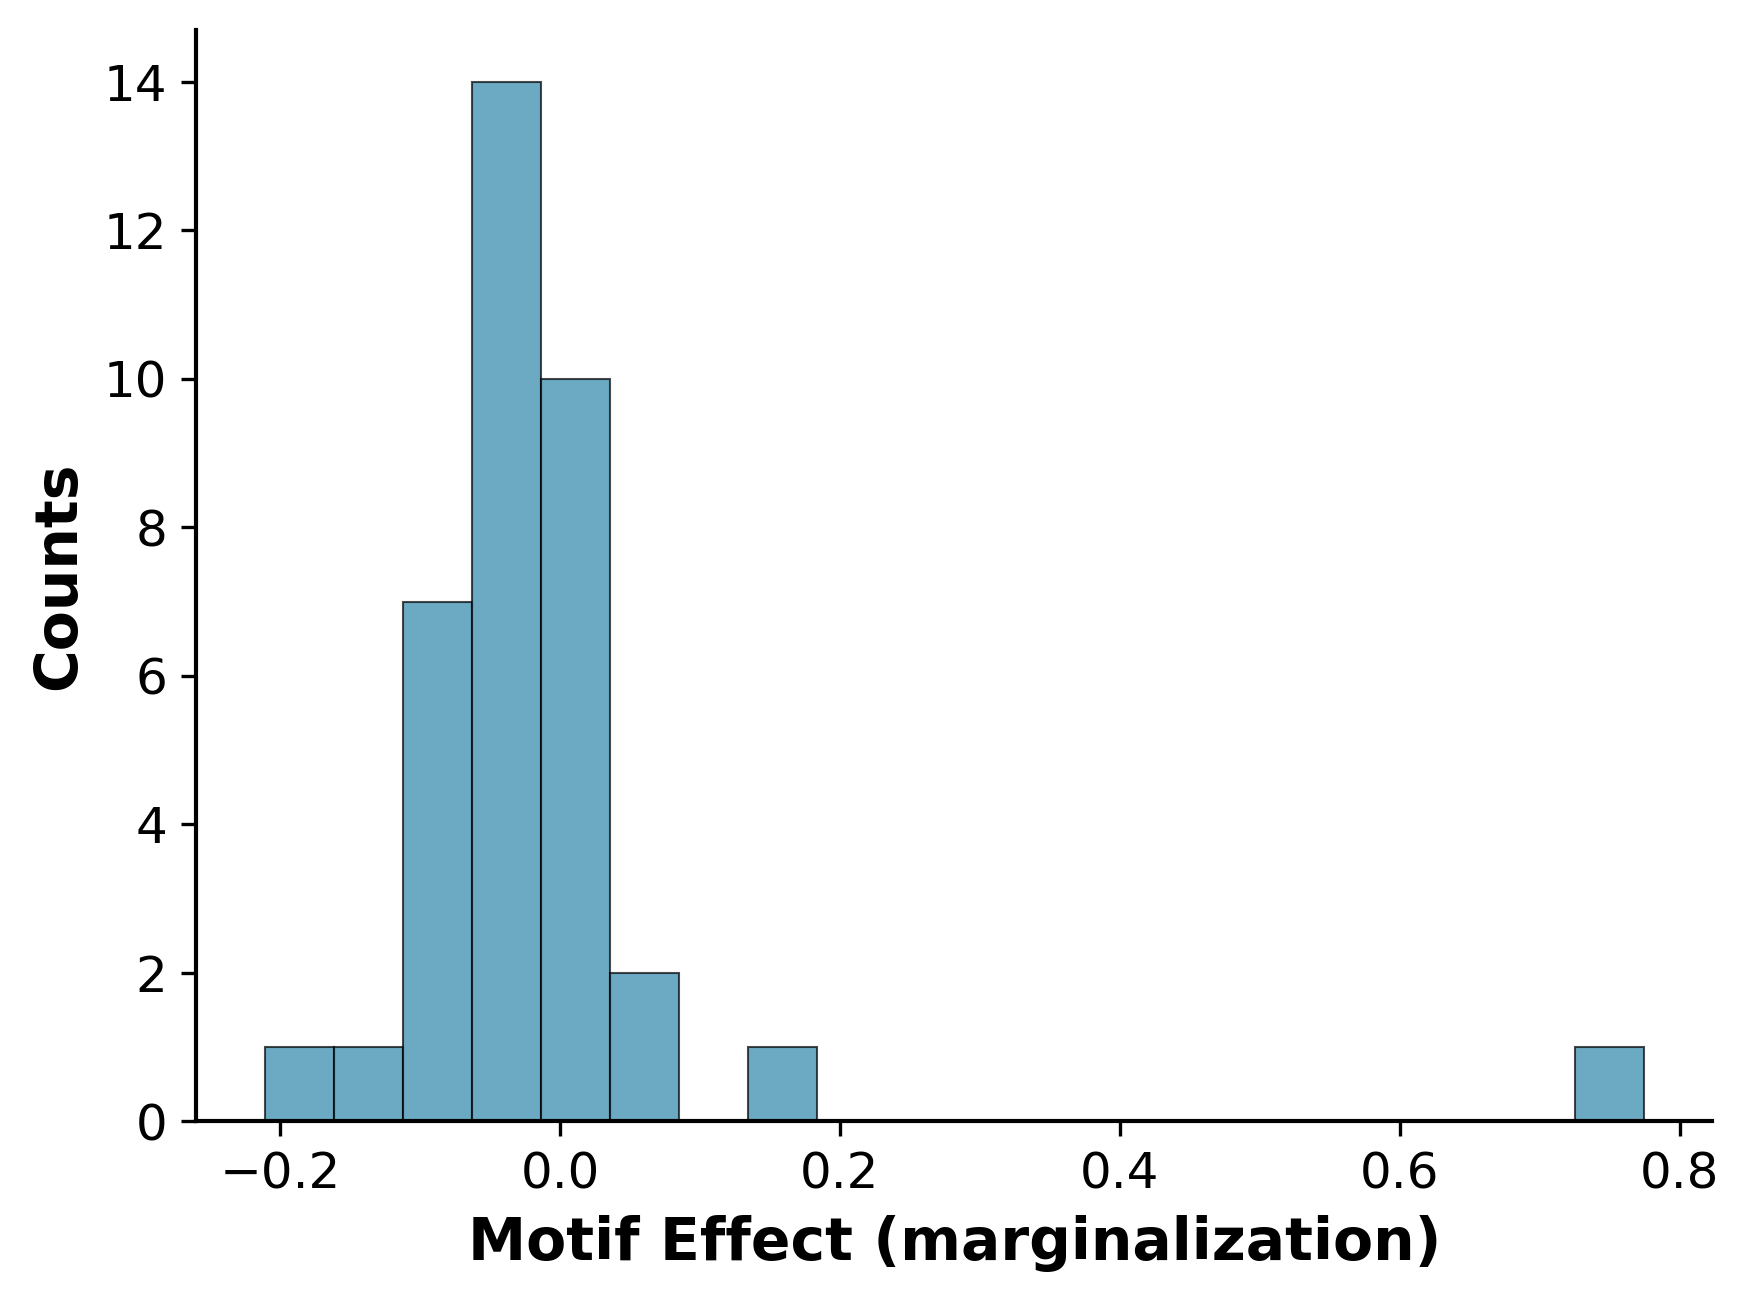

In [220]:
average_leakage_effect = [np.mean(v) for v in motif_effect_results.values()]

# Set publication-quality parameters
plt.style.use('default')  # Start with clean default style
matplotlib.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.format': 'pdf',
    'pdf.fonttype': 42,  # This ensures text is preserved as text in PDF
    'ps.fonttype': 42,   # This ensures text is preserved as text in PDF
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Create the figure with appropriate size for publication
fig, ax = plt.subplots(figsize=(6, 4.5))  # Standard single-column figure size

# Create the histogram with publication-appropriate styling
n, bins, patches = ax.hist(average_leakage_effect, bins=20, 
                          color='#2E86AB',  # Professional blue color
                          alpha=0.7,
                          edgecolor='black',
                          linewidth=0.5)

# Set labels with proper formatting
ax.set_xlabel('Motif Effect (marginalization)', fontweight='bold')
ax.set_ylabel('Counts', fontweight='bold')

# Improve the appearance
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# Add grid for better readability (optional)
#ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
#ax.set_axisbelow(True)

# Ensure integer y-axis ticks if appropriate
if max(n) < 50:  # Adjust threshold as needed
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

# Tight layout to optimize space usage
plt.tight_layout()

# Save as PDF with text preserved
plt.savefig('motif_effects_histogram.pdf', 
           dpi=300, 
           bbox_inches='tight',
           facecolor='white',
           edgecolor='none')

plt.show()

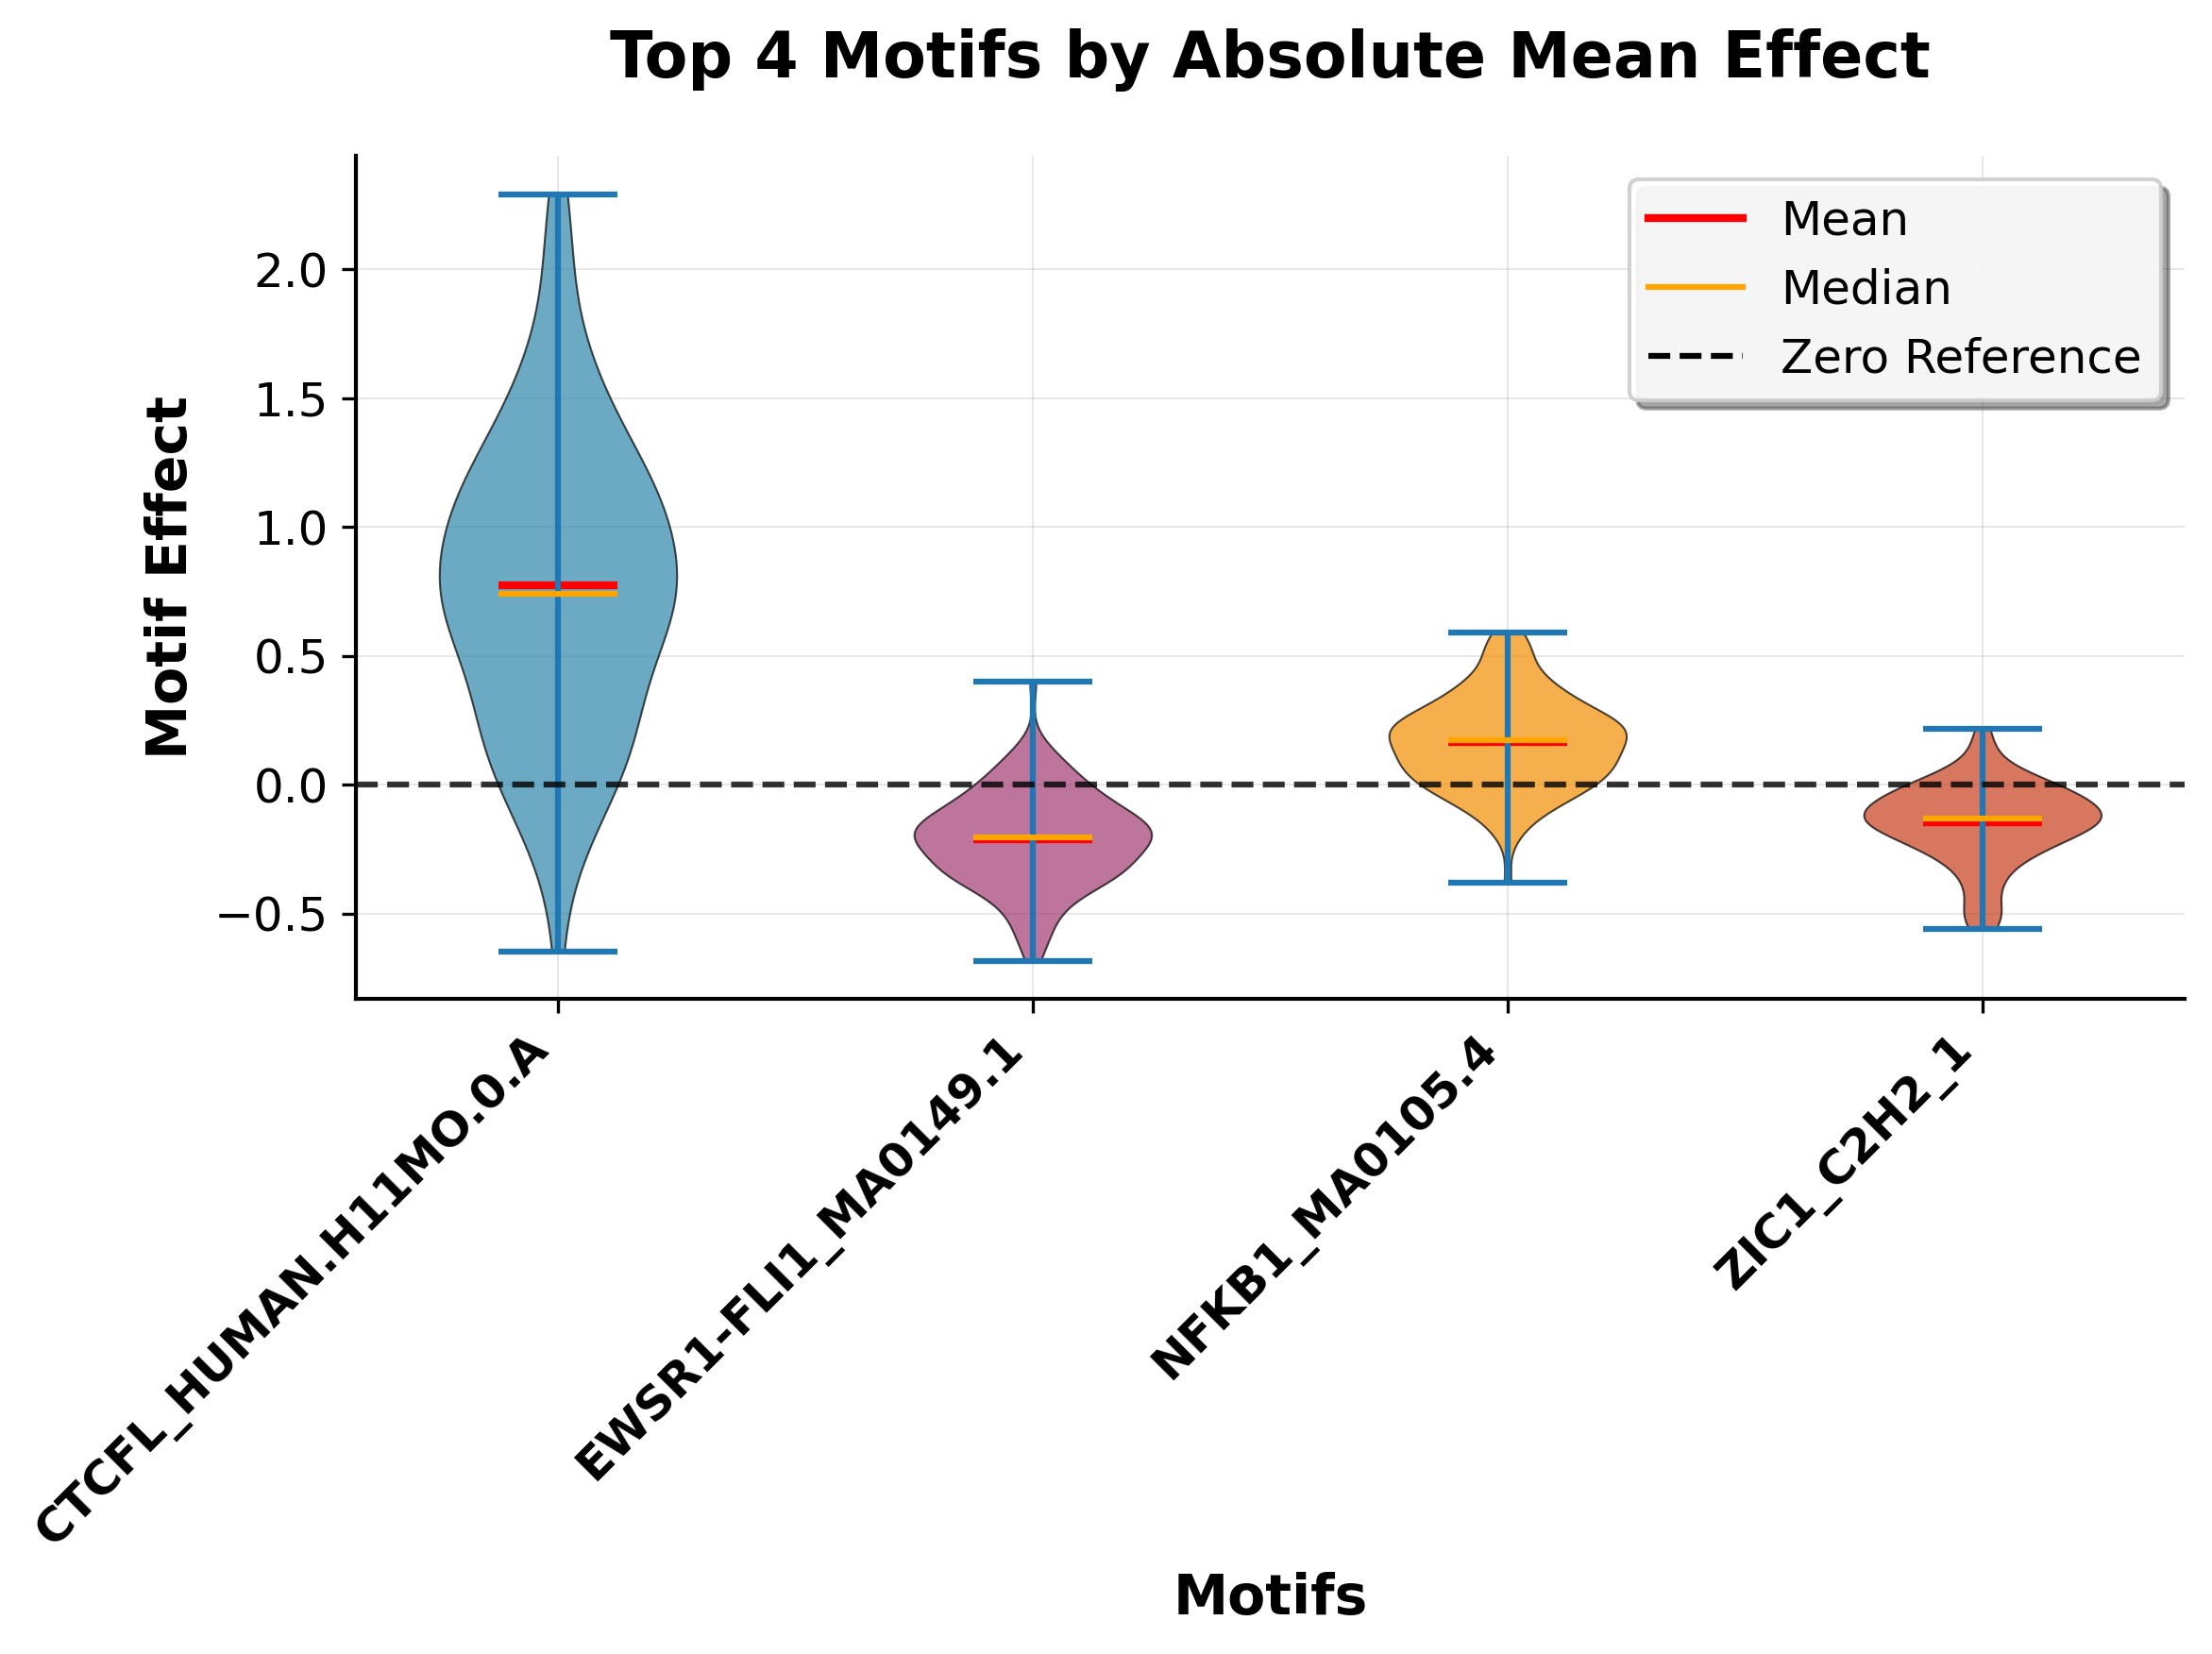

Top 4 motifs by absolute mean effect:
CTCFL_HUMAN.H11MO.0.A: 0.7742
EWSR1-FLI1_MA0149.1: -0.2106
NFKB1_MA0105.4: 0.1651
ZIC1_C2H2_1: -0.1471


In [227]:
# Set publication-quality parameters
matplotlib.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.format': 'pdf',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Get the 4 motifs with highest absolute mean values
sorted_motifs = dict(sorted(motif_effect_results.items(), 
                           key=lambda x: abs(x[1].mean()), 
                           reverse=True))
top_4_motifs = list(sorted_motifs.keys())[:4]

# Create publication-quality violin plot
fig, ax = plt.subplots(figsize=(8, 6))

# Prepare data for violin plot
data_for_violin = [motif_effect_results[motif] for motif in top_4_motifs]

# Define colors for each violin
colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D']

# Create violin plot with professional styling
violin_parts = ax.violinplot(data_for_violin, positions=range(1, 5), 
                            showmeans=True, showmedians=True)

# Style the violin plots with different colors
for i, pc in enumerate(violin_parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.7)
    pc.set_edgecolor('black')
    pc.set_linewidth(0.5)

# Style the statistical lines
violin_parts['cmeans'].set_color('red')
violin_parts['cmeans'].set_linewidth(2)
violin_parts['cmedians'].set_color('orange')
violin_parts['cmedians'].set_linewidth(1.5)

# Highlight zero line
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.8, zorder=10)

# Set labels with proper formatting
ax.set_xticks(range(1, 5))
ax.set_xticklabels(top_4_motifs, rotation=45, ha='right', fontweight='bold')
ax.set_ylabel('Motif Effect', fontweight='bold')
ax.set_xlabel('Motifs', fontweight='bold')
ax.set_title('Top 4 Motifs by Absolute Mean Effect', fontweight='bold', pad=20)

# Improve the appearance
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

# Add subtle grid
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5, zorder=0)
ax.set_axisbelow(True)

# Add a legend for the statistical lines
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='red', linewidth=2, label='Mean'),
    Line2D([0], [0], color='orange', linewidth=1.5, label='Median'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=1.5, label='Zero Reference')
]
ax.legend(handles=legend_elements, loc='upper right', frameon=True, 
          fancybox=True, shadow=True, framealpha=0.9)

# Tight layout
plt.tight_layout()

# Save as PDF
plt.savefig('top_4_motifs_violin_plot.pdf', 
           dpi=300, 
           bbox_inches='tight',
           facecolor='white',
           edgecolor='none')

plt.show()

# Print the mean values for reference
print("Top 4 motifs by absolute mean effect:")
for motif in top_4_motifs:
    mean_val = motif_effect_results[motif].mean()
    print(f"{motif}: {mean_val:.4f}")

CTCFL_HUMAN.H11MO.0.A


/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/tangermeme/deep_lift_shap.py:436: RuntimeWarning: Convergence deltas too high: tensor([4.2975e-05, 2.3246e-04, 1.2738e-04, 1.1686e-04, 2.2030e-04, 2.0256e-03,
        3.0130e-05, 3.3802e-04, 3.5220e-04, 9.2626e-05, 1.0192e-04, 3.3551e-04,
        1.5932e-04, 1.5864e-04, 5.7757e-05, 8.3208e-05, 1.0309e-04, 1.0583e-04,
        2.3130e-04, 1.1706e-04, 2.3186e-04, 4.4709e-04, 2.1225e-04, 2.3901e-04,
        1.7095e-04, 5.1230e-05, 9.9599e-05, 6.3896e-05, 1.0437e-04, 5.1826e-05,
        1.0681e-04, 1.5900e-04], device='cuda:0', grad_fn=<AbsBackward0>)
  warnings.warn("Convergence deltas too high: " +
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/tangermeme/deep_lift_shap.py:436: RuntimeWarning: Convergence deltas too high: tensor([2.0361e-04, 7.1526e-06, 1.6928e-04, 2.1338e-05, 3.8683e-04, 3.9005e-04,
        4.2796e-05, 1.5743e-03, 1.8668e-04, 9.1314e-05, 5.3453e-04, 2.3603e-04,
        1.

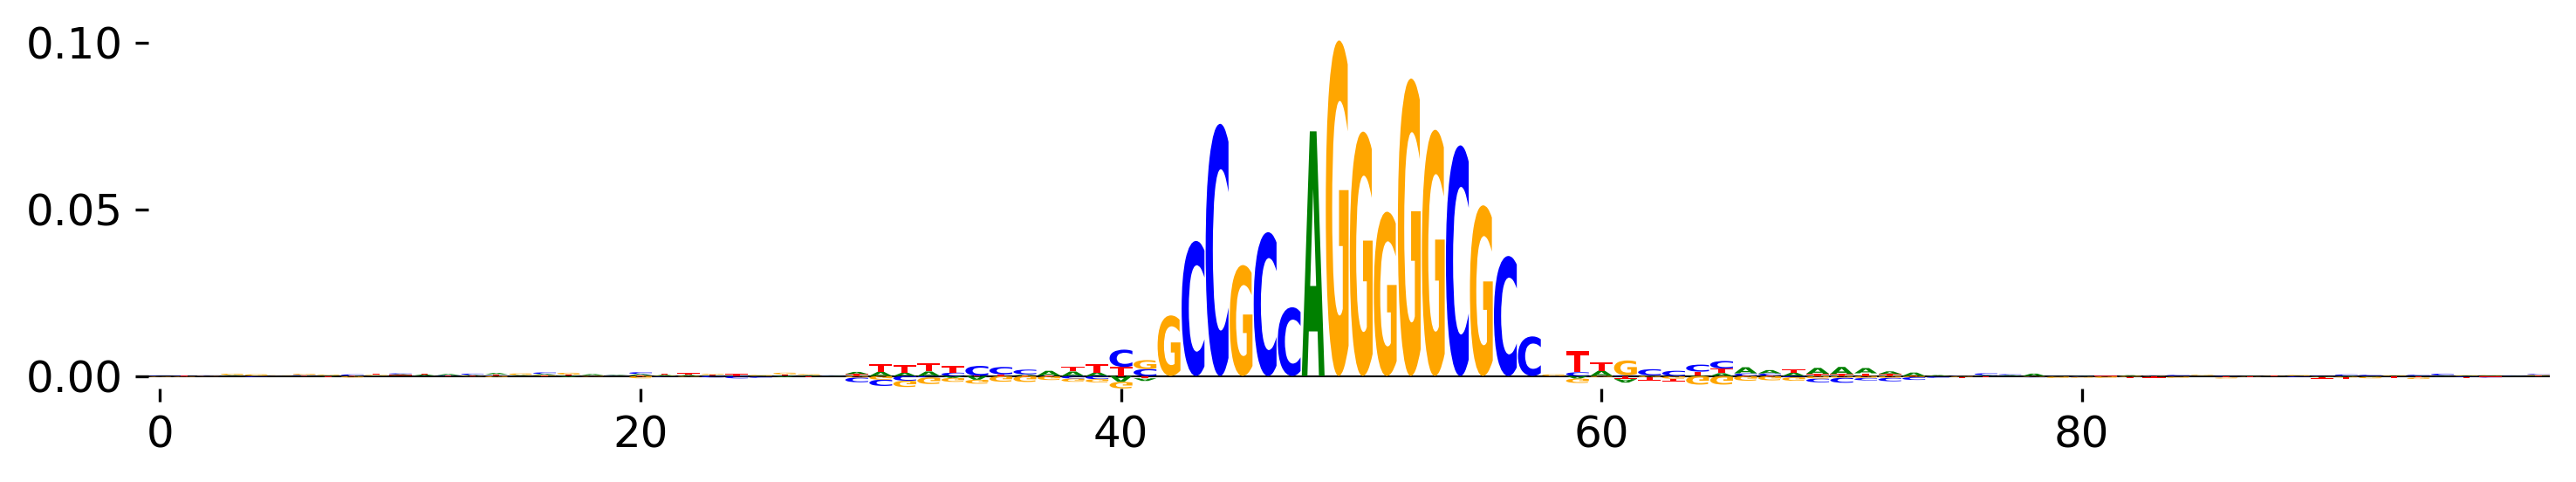

In [223]:
# Set up matplotlib for publication-quality output with text recognition
matplotlib.rcParams['pdf.fonttype'] = 42  # Ensures text is saved as text, not paths
matplotlib.rcParams['ps.fonttype'] = 42   # For EPS compatibility
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['axes.linewidth'] = 1.2

X = random_one_hot((100, 4, 2000)).type(torch.float32)
motif_name = "CTCFL_HUMAN.H11MO.0.A"
motif_sample = filtered_motifs_dict[motif_name]
X = substitute(X,motif_sample)
print(motif_name)
X_attr = deep_lift_shap(mdl, X, target=2002, random_state=0)

# Create the figure
plt.figure(figsize=(10, 2), dpi=300)
ax = plt.subplot(111)

# Your plot
plot_logo(X_attr.mean(axis=0)[:, 950:1050], ax=ax)

# Improve layout
plt.tight_layout()

# Save as PDF with high quality settings and text recognition
plt.savefig(f'logo_plot_{motif_name}.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight', 
            facecolor='white', 
            edgecolor='none',
            backend='pdf')

# Display the plot
plt.show()

EWSR1-FLI1_MA0149.1


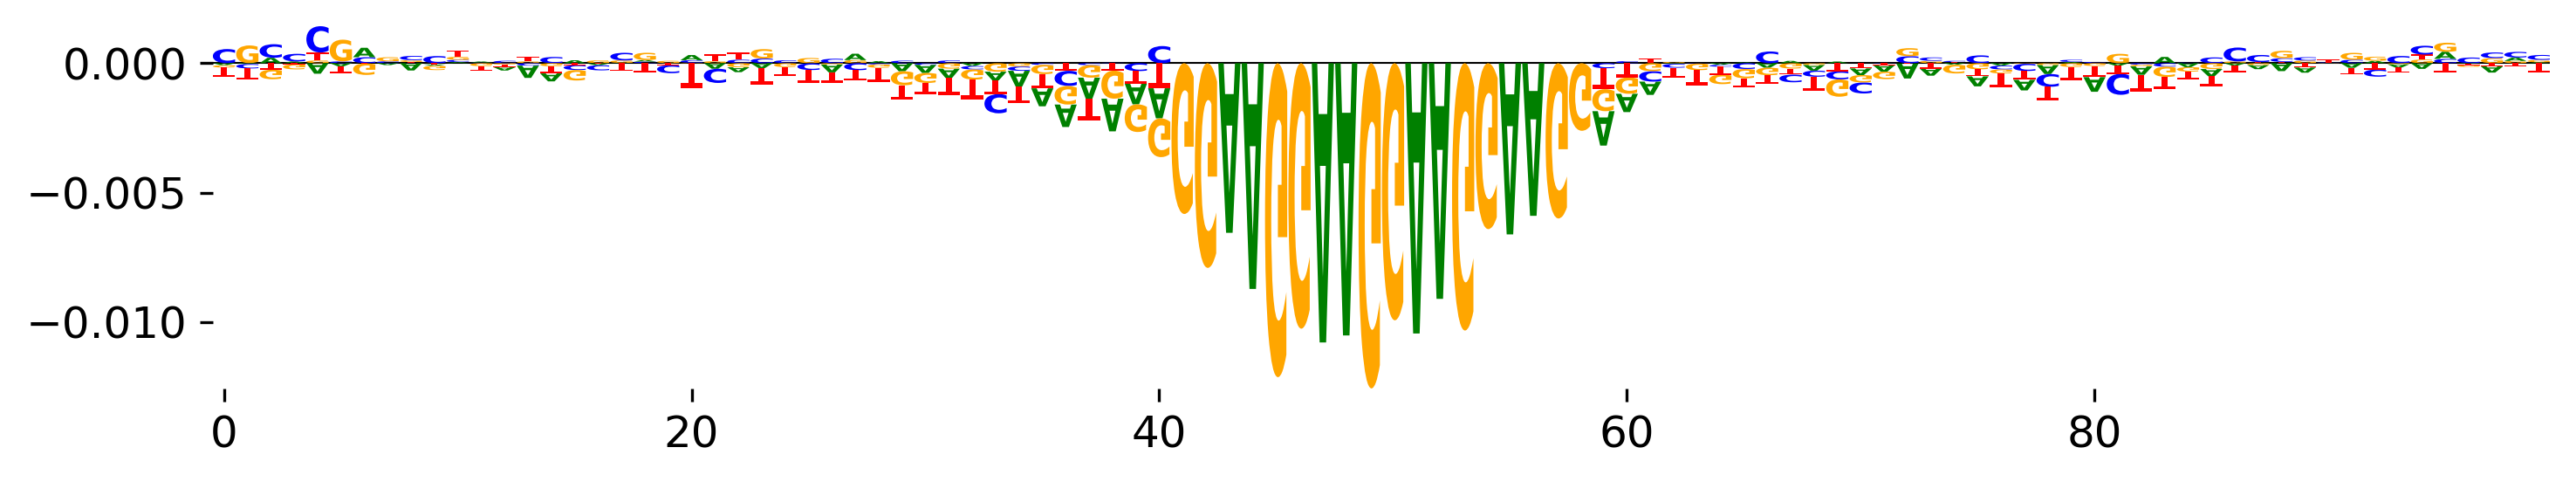

In [224]:
# Set up matplotlib for publication-quality output with text recognition
matplotlib.rcParams['pdf.fonttype'] = 42  # Ensures text is saved as text, not paths
matplotlib.rcParams['ps.fonttype'] = 42   # For EPS compatibility
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['axes.linewidth'] = 1.2

X = random_one_hot((100, 4, 2000)).type(torch.float32)
motif_name = "EWSR1-FLI1_MA0149.1"
motif_sample = filtered_motifs_dict[motif_name]
X = substitute(X,motif_sample)
print(motif_name)
X_attr = deep_lift_shap(mdl, X, target=2002, random_state=0)

# Create the figure
plt.figure(figsize=(10, 2), dpi=300)
ax = plt.subplot(111)

# Your plot
plot_logo(X_attr.mean(axis=0)[:, 950:1050], ax=ax)

# Improve layout
plt.tight_layout()

# Save as PDF with high quality settings and text recognition
plt.savefig(f'logo_plot_{motif_name}.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight', 
            facecolor='white', 
            edgecolor='none',
            backend='pdf')

# Display the plot
plt.show()

NFKB1_MA0105.4


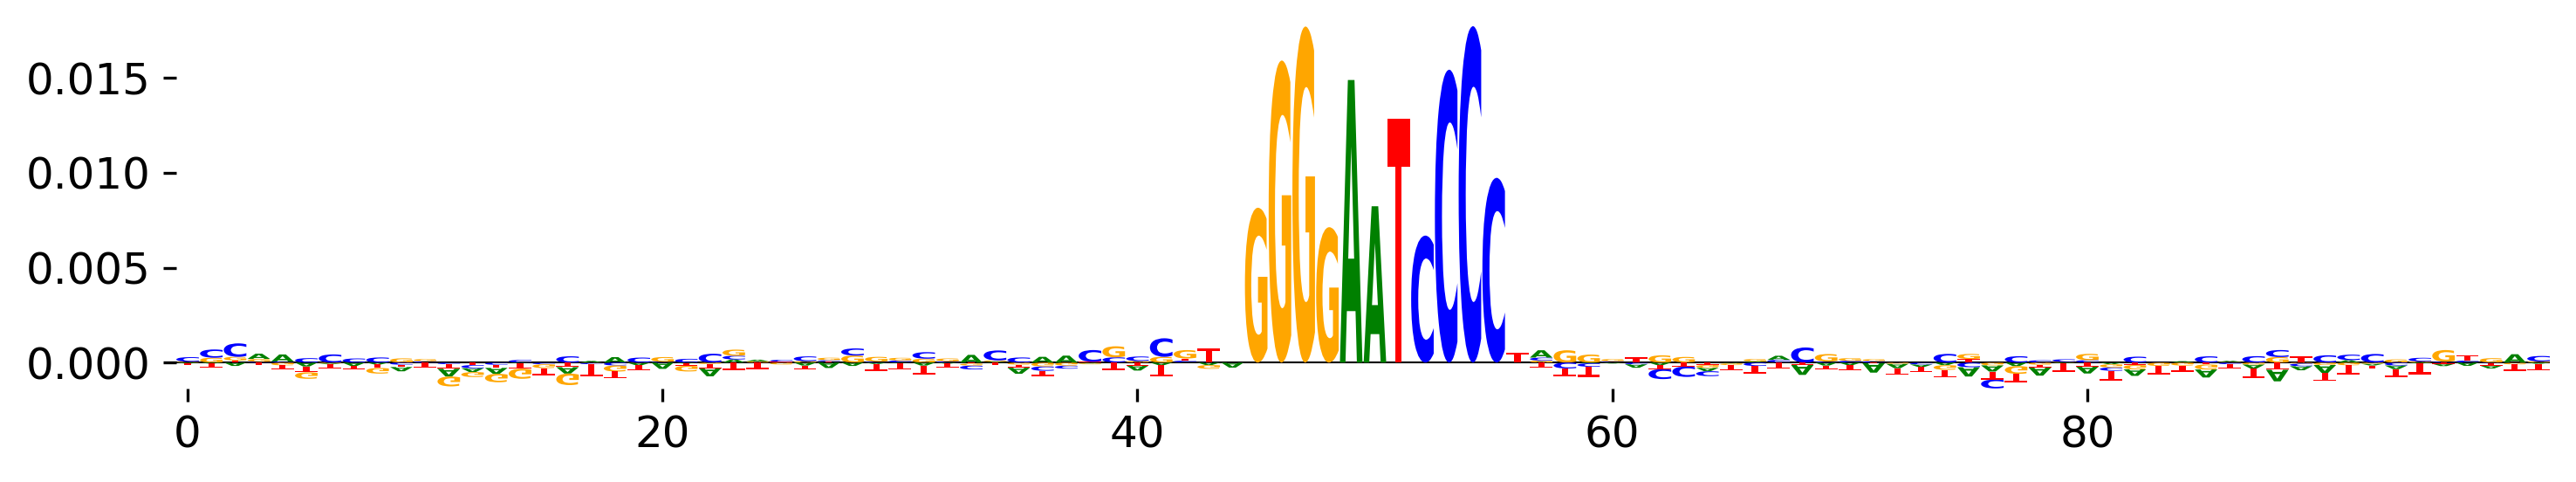

In [225]:
# Set up matplotlib for publication-quality output with text recognition
matplotlib.rcParams['pdf.fonttype'] = 42  # Ensures text is saved as text, not paths
matplotlib.rcParams['ps.fonttype'] = 42   # For EPS compatibility
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['axes.linewidth'] = 1.2

X = random_one_hot((100, 4, 2000)).type(torch.float32)
motif_name = "NFKB1_MA0105.4"
motif_sample = filtered_motifs_dict[motif_name]
X = substitute(X,motif_sample)
print(motif_name)
X_attr = deep_lift_shap(mdl, X, target=2002, random_state=0)

# Create the figure
plt.figure(figsize=(10, 2), dpi=300)
ax = plt.subplot(111)

# Your plot
plot_logo(X_attr.mean(axis=0)[:, 950:1050], ax=ax)

# Improve layout
plt.tight_layout()

# Save as PDF with high quality settings and text recognition
plt.savefig(f'logo_plot_{motif_name}.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight', 
            facecolor='white', 
            edgecolor='none',
            backend='pdf')

# Display the plot
plt.show()

ZIC1_C2H2_1


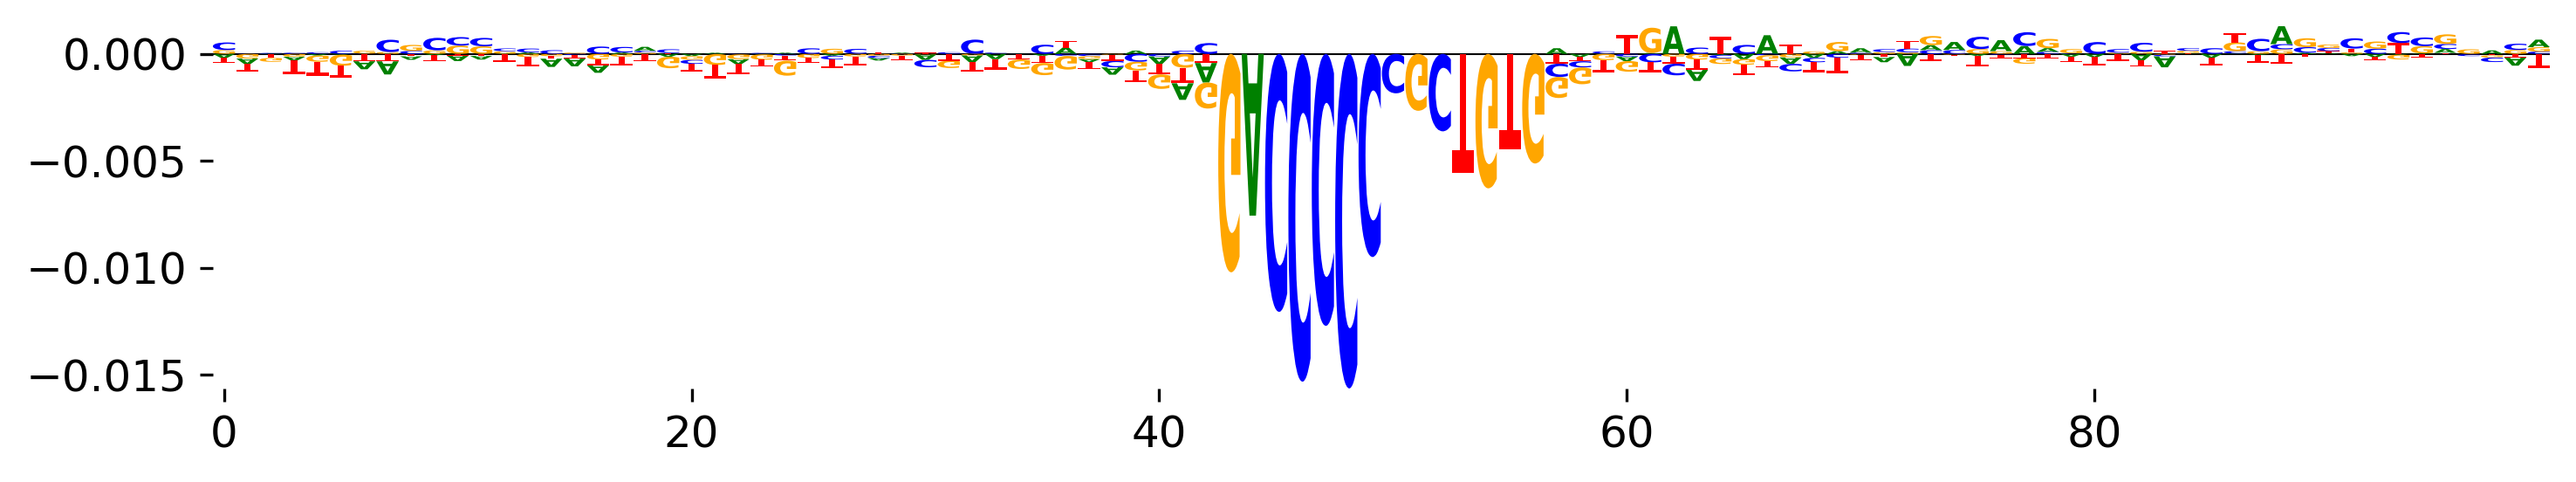

In [226]:
# Set up matplotlib for publication-quality output with text recognition
matplotlib.rcParams['pdf.fonttype'] = 42  # Ensures text is saved as text, not paths
matplotlib.rcParams['ps.fonttype'] = 42   # For EPS compatibility
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['axes.linewidth'] = 1.2

X = random_one_hot((100, 4, 2000)).type(torch.float32)
motif_name = "ZIC1_C2H2_1"
motif_sample = filtered_motifs_dict[motif_name]
X = substitute(X,motif_sample)
print(motif_name)
X_attr = deep_lift_shap(mdl, X, target=2002, random_state=0)

# Create the figure
plt.figure(figsize=(10, 2), dpi=300)
ax = plt.subplot(111)

# Your plot
plot_logo(X_attr.mean(axis=0)[:, 950:1050], ax=ax)

# Improve layout
plt.tight_layout()

# Save as PDF with high quality settings and text recognition
plt.savefig(f'logo_plot_{motif_name}.pdf', 
            format='pdf', 
            dpi=300, 
            bbox_inches='tight', 
            facecolor='white', 
            edgecolor='none',
            backend='pdf')

# Display the plot
plt.show()

Performing Wilcoxon signed-rank tests...

Results:
Total motifs tested: 37
Significant motifs (FDR-corrected p < 0.05): 23
Proportion significant: 0.622 (62.2%)


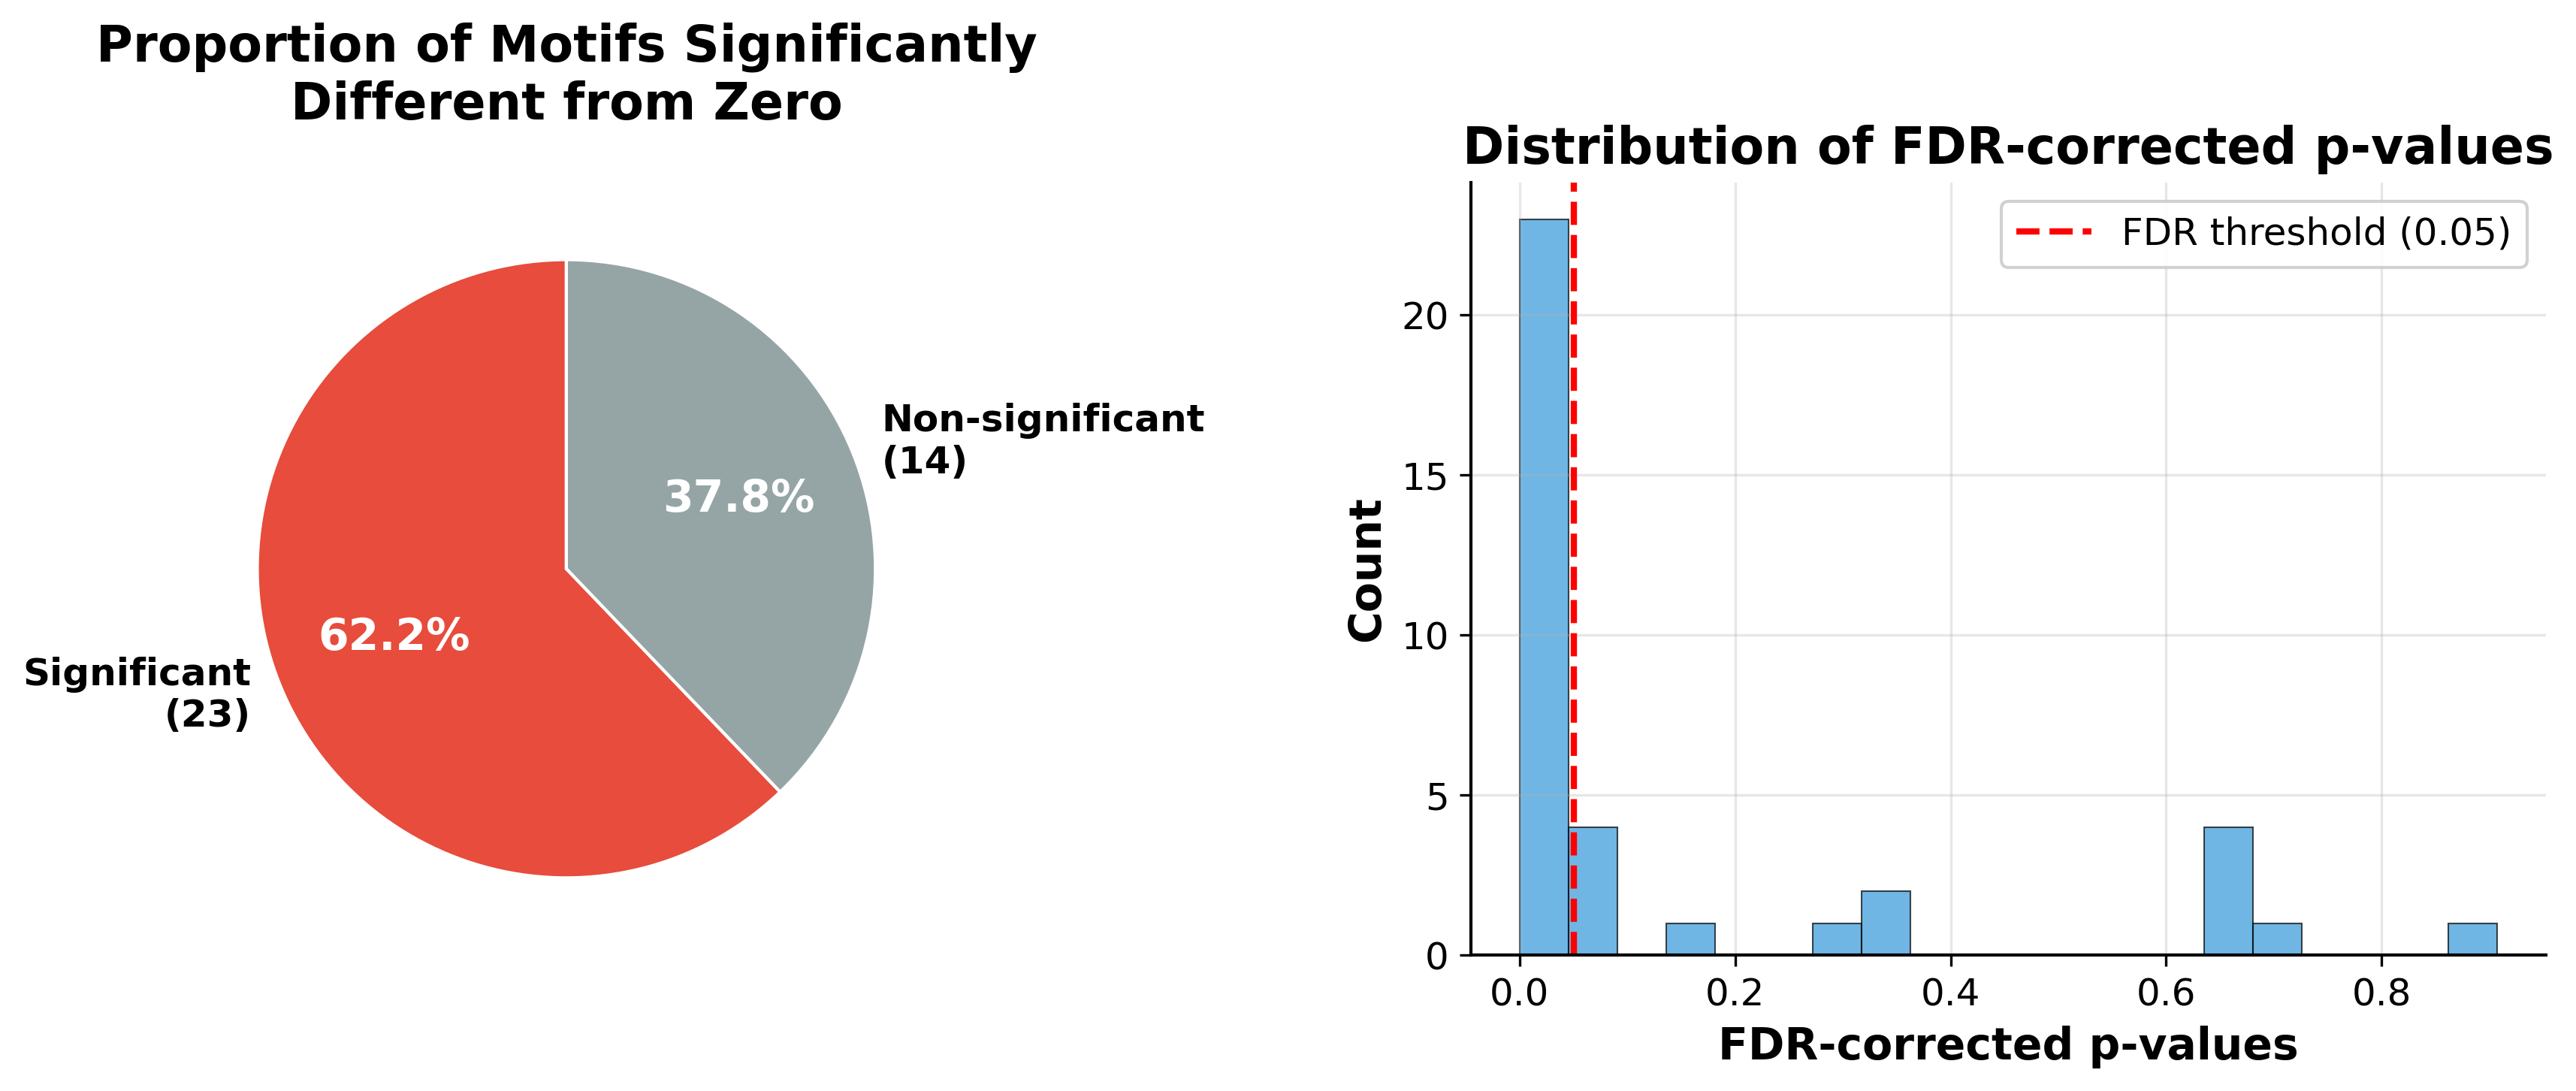


Top 10 most significant motifs (FDR-corrected):
 1. CTCFL_HUMAN.H11MO.0.A: mean effect = 0.7742, FDR p-value = 5.14e-15
 2. EWSR1-FLI1_MA0149.1: mean effect = -0.2106, FDR p-value = 7.93e-14
 3. ZIC1_C2H2_1: mean effect = -0.1471, FDR p-value = 1.09e-12
 4. NFKB1_MA0105.4: mean effect = 0.1651, FDR p-value = 8.55e-12
 5. MZF1_MA0057.1: mean effect = -0.0800, FDR p-value = 1.37e-08
 6. FEZF1_HUMAN.H11MO.0.C: mean effect = -0.0668, FDR p-value = 2.06e-08
 7. PLAG1_MA0163.1: mean effect = -0.0916, FDR p-value = 7.71e-08
 8. MZF1_HUMAN.H11MO.0.B: mean effect = -0.0689, FDR p-value = 2.03e-06
 9. STAT6_HUMAN.H11MO.0.B: mean effect = -0.0503, FDR p-value = 6.75e-06
10. ZN257_HUMAN.H11MO.0.C: mean effect = -0.0477, FDR p-value = 1.01e-05


In [230]:
# Perform Wilcoxon signed-rank tests for each motif
motif_names = list(motif_effect_results.keys())
p_values = []
test_statistics = []

print("Performing Wilcoxon signed-rank tests...")
for motif, effects in motif_effect_results.items():
    # Wilcoxon signed-rank test against zero
    # Remove zeros if any (Wilcoxon can't handle them)
    effects_no_zero = effects[effects != 0]
    
    if len(effects_no_zero) > 0:
        stat, p_val = wilcoxon(effects_no_zero, alternative='two-sided')
        p_values.append(p_val)
        test_statistics.append(stat)
    else:
        p_values.append(1.0)  # If all zeros, not significant
        test_statistics.append(0)

p_values = np.array(p_values)

# Apply multiple hypothesis correction (Benjamini-Hochberg FDR)
rejected, p_adjusted, alpha_sidak, alpha_bonf = multipletests(
    p_values, alpha=0.05, method='fdr_bh'
)

# Calculate proportions
total_motifs = len(motif_names)
significant_count = np.sum(rejected)
proportion_significant = significant_count / total_motifs

print(f"\nResults:")
print(f"Total motifs tested: {total_motifs}")
print(f"Significant motifs (FDR-corrected p < 0.05): {significant_count}")
print(f"Proportion significant: {proportion_significant:.3f} ({proportion_significant*100:.1f}%)")

# Create visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Set publication quality parameters
matplotlib.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Plot 1: Clean, flat pie chart
sizes = [significant_count, total_motifs - significant_count]
labels = [f'Significant\n({significant_count})', f'Non-significant\n({total_motifs - significant_count})']
colors = ['#E74C3C', '#95A5A6']

wedges, texts, autotexts = ax1.pie(sizes, labels=labels, colors=colors, 
                                  autopct='%1.1f%%', startangle=90,
                                  textprops={'fontweight': 'bold', 'fontsize': 12},
                                  wedgeprops={'linewidth': 1, 'edgecolor': 'white'})

# Make percentage text bold and larger
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(14)

ax1.set_title('Proportion of Motifs Significantly\nDifferent from Zero', 
              fontweight='bold', pad=20)

# Plot 2: Histogram of p-values with significance threshold
ax2.hist(p_adjusted, bins=20, color='#3498DB', alpha=0.7, edgecolor='black', linewidth=0.5)
ax2.axvline(x=0.05, color='red', linestyle='--', linewidth=2, label='FDR threshold (0.05)')
ax2.set_xlabel('FDR-corrected p-values', fontweight='bold')
ax2.set_ylabel('Count', fontweight='bold')
ax2.set_title('Distribution of FDR-corrected p-values', fontweight='bold')
ax2.legend(frameon=True, fancybox=True, shadow=False, framealpha=0.9)
ax2.grid(True, alpha=0.3)

# Clean up appearance
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_linewidth(1)
ax2.spines['bottom'].set_linewidth(1)

plt.tight_layout()

# Save the plot
plt.savefig('motif_significance_analysis.pdf', 
           dpi=300, 
           bbox_inches='tight',
           facecolor='white',
           edgecolor='none')

plt.show()

# Print top significant motifs
print(f"\nTop 10 most significant motifs (FDR-corrected):")
significant_indices = np.where(rejected)[0]
if len(significant_indices) > 0:
    # Sort by adjusted p-value
    sorted_sig_indices = significant_indices[np.argsort(p_adjusted[significant_indices])]
    
    for i, idx in enumerate(sorted_sig_indices[:10]):
        motif = motif_names[idx]
        mean_effect = np.mean(motif_effect_results[motif])
        print(f"{i+1:2d}. {motif}: mean effect = {mean_effect:.4f}, "
              f"FDR p-value = {p_adjusted[idx]:.2e}")
else:
    print("No significant motifs found.")